# Dynamics via Trotterization

Here, we show a simple example of how to simulate dynamics using Trotterization and extract absolute energies from FFT spectrum estimation. We use $\mathrm{C_2H_6S_2}$ (dimethyl disulfide) as an example.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from rdkit import Chem
from rdkit.Chem import AllChem
import cupynumeric as np
import trovolut as trv

In [2]:
mol = Chem.AddHs(Chem.MolFromSmiles("CSSC"))
AllChem.EmbedMolecule(mol, AllChem.ETKDGv3())
AllChem.UFFOptimizeMolecule(mol)

conf = mol.GetConformer()
atoms = [a.GetSymbol() for a in mol.GetAtoms()]
xyz = (
    f"{len(atoms)}\ndmds generated by RDKit\n"
    + "\n".join(
        f"{s} {conf.GetAtomPosition(i).x:.8f} "
        f"{conf.GetAtomPosition(i).y:.8f} "
        f"{conf.GetAtomPosition(i).z:.8f}"
        for i, s in enumerate(atoms)
    )
)

# Build the electronic Hamiltonian with minimal active space (4 qubits)
H_fermion = trv.qm.ElectronicHamiltonian.from_xyz(
    xyz_source=xyz,
    basis="sto-3g",
    charge=0,
    spin_mult=1,
    use_gpu4pyscf=False,
    freeze_core=True,
    n_core_keep=1,  # Just HOMO
    n_virt_keep=1,  # Just LUMO -> 2 spatial orbs = 4 qubits (dim 16)
)

# Convert to qubit Hamiltonian via Jordan-Wigner
H_elec = H_fermion.to_qubits()

converged SCF energy = -864.654938672564


In [ ]:
# Get info about the Hamiltonian
meta = H_fermion.meta
print(f"Active space: {meta['n_act_spatial']} spatial orbitals, {meta['n_electrons']} electrons")
print(f"Number of qubits: {meta['n_spin_orb']}")
print(f"Hilbert space dimension: {2**meta['n_spin_orb']}")

Active space: 2 spatial orbitals, 2 electrons
Number of qubits: 4
Hilbert space dimension: 16


We prepare the HF state and time-evolve it using exact matrix exponentiation.

In [ ]:
qmeta = H_elec.decompose()
hamcoeffs = H_elec.terms() # ignore the identity term as e^{c*I} is just a global phase

print("first 5 terms:")
for term in qmeta["terms"][1:6]:
    print(term)

first 5 terms:
{'coeff': np.float64(0.2992851676586597), 'pauli': 'Z0'}
{'coeff': np.float64(0.00010200044559601862), 'pauli': 'Y0Z1Y2'}
{'coeff': np.float64(0.00010200044559601862), 'pauli': 'X0Z1X2'}
{'coeff': np.float64(0.29928516765865965), 'pauli': 'Z1'}
{'coeff': np.float64(0.0001020004455960184), 'pauli': 'Y1Z2Y3'}


In [ ]:
hams = [term['coef'] * term['matrix'] for term in hamcoeffs]

In [ ]:
# Get the HF state
psi0 = H_fermion.hf_state()
n_qubits = meta['n_spin_orb']

print(f"HF state: |{H_fermion.hf_bitstring()}>")

HF state: |11000000>


Now, we compute the spectrum of the Hamiltonian using the time-evolved states obtained via Trotterization.

In [ ]:
from trovolut.utils.signal_processing import estimate_spectrum
from trovolut.qm.dynamics import suzuki_step

In [ ]:
total_time = 10
n_time_steps = 1000
dt = total_time / n_time_steps

psit = np.zeros((n_time_steps, psi0.size), dtype=complex)
psit[0] = psi0
for i, t in enumerate(np.linspace(0, total_time, n_time_steps)[1:], start=1):
    psit[i] = suzuki_step(hams, dt=dt, order=2) @ psit[i - 1]

psit /= np.linalg.norm(psit, axis=1)[:, np.newaxis]

In [ ]:
# Estimate spectrum from FFT (gives relative energies)
res = estimate_spectrum(psit, dt, method="fft", n_levels=5)
raw_energies = res[3]["energies"]
print(f"FFT estimated energies (relative): {raw_energies}")

FFT estimated energies (relative): [0.59032437 1.2197023  1.84904715 2.47836038 3.10764336]


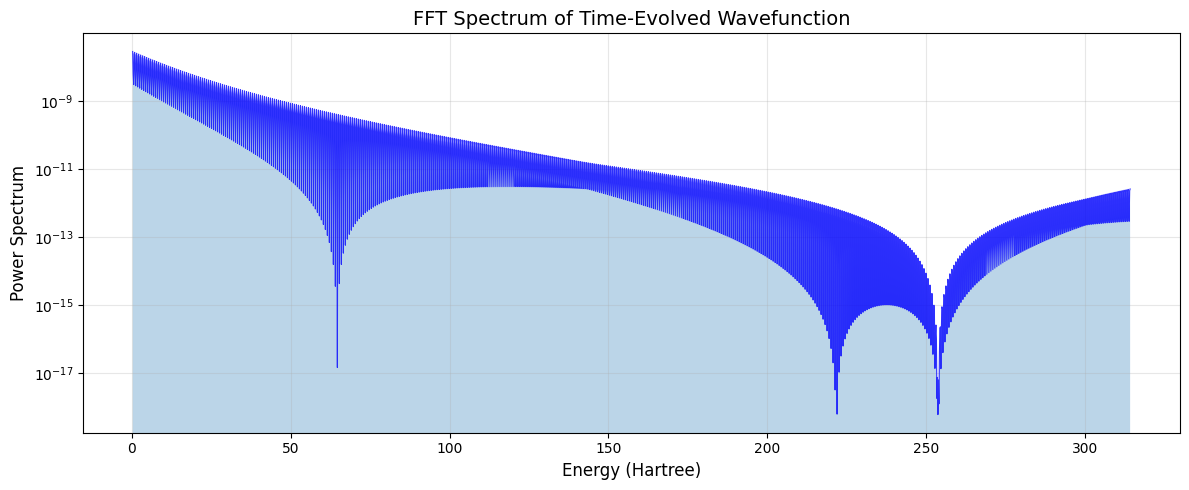

In [ ]:
from trovolut.utils.signal_processing import plot_fft_spectrum

fig, ax, _ = plot_fft_spectrum(psit, dt, max_energy=1000, log_scale=True)

## Comparison: FFT vs Exact Diagonalization

We compare the energies estimated from the FFT of the time-evolved state with the exact eigenvalues obtained by diagonalization.

In [ ]:
# Compute the exact spectrum by diagonalizing the Hamiltonian
evals, evecs = np.linalg.eigh(H_mat)

# Find eigenvalues in the n-electron sector
n_e = H_fermion.n_electrons
sector_mask = np.array([bin(i).count('1') == n_e for i in range(2**n_qubits)])
sector_evals = np.sort(evals[sector_mask])

print(f"Exact {n_e}-electron eigenvalues (lowest 5):")
for i, E in enumerate(sector_evals[:5]):
    print(f"  E_{i} = {float(E):.6f} Ha")

Exact 4-electron eigenvalues (lowest 5):
  E_0 = -1341.642183
  E_1 = -1341.598212
  E_2 = -1339.842518
  E_3 = -1339.842518
  E_4 = -1339.842518


In [ ]:
# Compute overlap of HF state with exact eigenstates
overlaps = np.abs(evecs.T.conj() @ psi0)**2

# Find eigenstates with significant HF overlap (these will appear in FFT)
print("Eigenstates with significant HF overlap:")
print("-" * 60)
hf_overlaps = []
for i, (E, overlap) in enumerate(zip(evals, overlaps)):
    if overlap > 0.01:
        hf_overlaps.append((i, float(E), float(overlap)))
        print(f"  E_{i} = {float(E):12.6f} Ha,  |<HF|E_{i}>|² = {float(overlap):.4f}")

# Convert FFT energies from relative to absolute
# The FFT gives relative energies (E - E_ref). 
# We shift by aligning the dominant peak with the HF energy.
energy_offset = E_hf - float(raw_energies[0])
absolute_energies = raw_energies + energy_offset

print(f"\n" + "="*60)
print("FFT Estimated Energies (Absolute)")
print("="*60)
for i, E in enumerate(absolute_energies[:5]):
    print(f"  E_{i} = {float(E):.6f} Ha")

print("\n" + "="*60)
print("Comparison: FFT vs Exact Diagonalization")
print("="*60)
print(f"{'FFT':>12}  |  {'Exact':>12}  |  {'Error':>12}")
print("-" * 44)
for idx, (i, E_exact, overlap) in enumerate(hf_overlaps):
    if idx < len(absolute_energies):
        E_fft = float(absolute_energies[idx])
        error = E_fft - E_exact
        print(f"{E_fft:12.6f}  |  {E_exact:12.6f}  |  {error:+.6f}")
print("-" * 44)

Eigenstates with significant HF overlap:
------------------------------------------------------------
  Exact E_33 =   -1317.0808,  |<HF|E_33>|² = 0.9942

HF state energy <ψ_HF|H|ψ_HF> = -1317.0807

FFT estimated energies (absolute):
  E_0 = -1317.080700
  E_1 = -1316.451322
  E_2 = -1315.821977
  E_3 = -1315.192664
  E_4 = -1314.563381

------------------------------------------------------------
Comparison: FFT vs Exact Diagonalization
------------------------------------------------------------
  FFT:   -1317.0807  |  Exact:   -1317.0808  |  Error: +0.000061
------------------------------------------------------------
